<a href="https://colab.research.google.com/github/a01770768-oss/JobishViri/blob/main/prestaci%C3%B3n_viri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Running Habits in Mexico, and the analysis
**TABLE OF CONTENTS**

1. [Initial Setup](#scrollTo=3VhkF8sh4DEk)
2. [RQ1: Which age group represents the largest share of respondents?](#scrollTo=WiOv3ycP4DEo)
  - Pie
3. [RQ2: How often do respondents run per week?](#scrollTo=VcjS6qh74DEr)
  - bar

## 1. Initial Setup

### Description of DATASET
This dataset contains 60 simulated survey responses about running habits in Mexico.

Each row represents one respondent and their running habits.

Observations: 60 rows.

Variables: 2 original columns.


### Description of the Variables of Interest

### Description of the Variables of Interest

- **Age:** Gives the age of each respondent in years. It is a numerical variable.

- **Running_frequency:** Gives the number of days each respondent runs per week, grouped into categories. It is a categorical variable

- **AgeGP:** Gives the age group of each respondent. It is a categorical variable

In [31]:

file_path = 'https://raw.githubusercontent.com/a01770768-oss/Running-Viri/main/correr_mexico_datos.csv'

import pandas as pd

df = pd.read_csv(file_path)
df.head()


,Age,Running_frequency
0,49,3-4 days
1,38,1-2 days
2,53,3-4 days
3,17,1-2 days
4,30,3-4 days


In [32]:
file_path = 'correr_mexico_datos.csv'
df = pd.read_csv(file_path)
df.head()

,Age,Running_frequency
0,49,3-4 days
1,38,1-2 days
2,53,3-4 days
3,17,1-2 days
4,30,3-4 days


In [33]:
df.columns

Index(['Age', 'Running_frequency'], dtype='object')

In [34]:
favs = ['Age', 'Running_frequency']
ndf = df[favs]
ndf.head()

,Age,Running_frequency
0,49,3-4 days
1,38,1-2 days
2,53,3-4 days
3,17,1-2 days
4,30,3-4 days


In [35]:
ndf.shape

(60, 2)

In [ ]:
ndf = ndf.dropna()
ndf.isnull().any()

,0
Age,False
Running_frequency,False


[2. RQ1: Which age group represents the largest share of respondents?](#scrollTo=e8aNrmQz4DEg&line=6&uniqifier=1)

In [36]:
def age_cls(x):
    if x < 20:
        return 'Under 20'
    elif x < 30:
        return '20-29'
    elif x < 40:
        return '30-39'
    return '40+'

In [37]:
ndf['AgeGP'] = ndf['Age'].apply(age_cls)
ndf.head()

,Age,Running_frequency,AgeGP
0,49,3-4 days,40+
1,38,1-2 days,30-39
2,53,3-4 days,40+
3,17,1-2 days,Under 20
4,30,3-4 days,30-39


In [38]:
age_counts = pd.pivot_table(ndf, index='AgeGP', values='Age', aggfunc='count')
age_counts

,Age
AgeGP,
20-29,15
30-39,16
40+,24
Under 20,5


In [39]:
age_counts.rename(columns={'Age':'Count'}, inplace=True)
age_counts.reset_index(inplace=True)
age_counts

,AgeGP,Count
0,20-29,15
1,30-39,16
2,40+,24
3,Under 20,5


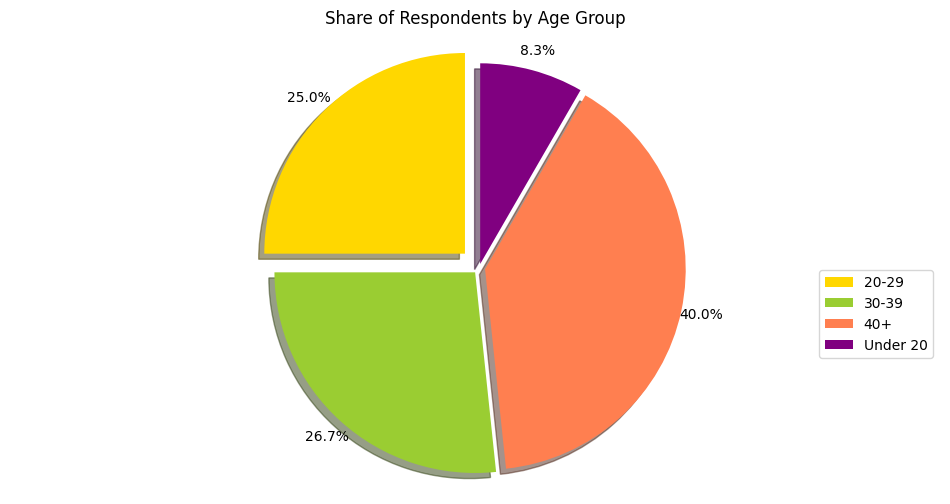

In [40]:
import matplotlib.pyplot as plt

explode_list = [0.1, 0.03, 0.03, 0.02]
colors = ['gold', 'yellowgreen', 'coral', 'purple']

age_counts['Count'].plot(
    kind='pie',
    figsize=(12, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,
    pctdistance=1.1,
    explode=explode_list,
    colors=colors
)

plt.axis('equal')
plt.legend(
    labels=age_counts['AgeGP'],
    bbox_to_anchor=(1, 0.5)
)
plt.title('Share of Respondents by Age Group')
plt.ylabel('')
plt.show()

**Insight:**  It shows the most common age group in this simulated sample. WHich is 40+

[3. RQ2: How often do respondents run per week?](#scrollTo=e8aNrmQz4DEg&line=6&uniqifier=1)

In [41]:
frequency_counts = pd.pivot_table(ndf, index='Running_frequency',
                                  values='Age', aggfunc='count')
frequency_counts

,Age
Running_frequency,
0 days,8
1-2 days,29
3-4 days,14
5+ days,9


In [ ]:
frequency_counts.rename(columns={'Age':'Count'}, inplace=True)
frequency_counts.reset_index(inplace=True)
frequency_counts

,Running_frequency,Count
0,0 days,8
1,1-2 days,29
2,3-4 days,14
3,5+ days,9


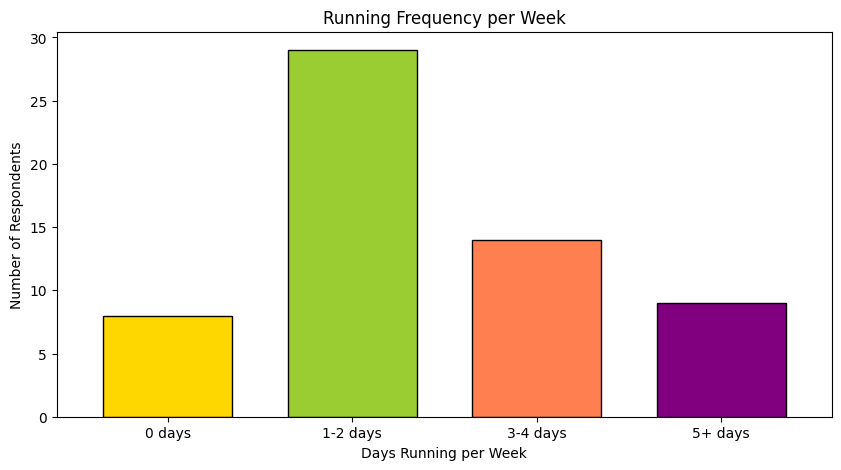

In [30]:
import matplotlib.pyplot as plt

colors = ['gold', 'yellowgreen', 'coral', 'purple']

frequency_counts['Count'].plot(
    kind='bar',
    figsize=(10, 5),
    color=colors,
    edgecolor='black',
    width=0.7
)

plt.title('Running Frequency per Week')
plt.xlabel('Days Running per Week')
plt.ylabel('Number of Respondents')

plt.xticks(
    ticks=range(len(frequency_counts)),
    labels=frequency_counts['Running_frequency'],
    rotation=0
)

plt.show()

**Insight:** The tallest bar shows the most common running frequency among respondents in this simulated sample. Which is 1-2 days

